# CS05 - Demand growth, reactive limits and voltage stability (IEEE 14-bus)

**Problem type:** operating limits under load growth; loadability and voltage collapse.
**Source:** Travaux pratiques, case 4, on the official IEEE 14-bus data (MATPOWER
`case14.m`) with thermal ratings from the IEEE PES benchmark library PGLib-OPF.

## 1. Context
Demand grows by 10 %, 20 % and 30 % (scenarios S1 to S3). We add S4 (+40 %) and S5 (+50 %)
to see what happens beyond. The exercise statement gave **illustrative** numbers; here we
compute them.

## 2. Exercise
For each scenario report: (1) minimum voltage, (2) number of buses below 0.95 p.u.,
(3) maximum line loading, (4) active losses, (5) reactive power from the generators.
Then: (6) why must generator reactive limits be enforced? (7) What is the maximum
loadability of the system, and what limits it?

## 3. Theory: reactive limits and voltage collapse
* A generator holds its bus voltage (PV bus) only while its reactive output stays within
  $[Q_{min}, Q_{max}]$. PyPSA's load flow does **not** enforce these limits: we apply the
  standard **PV to PQ switching** (`pscs.kpi.enforce_q_limits`): a generator that hits a
  limit is fixed at that limit and its bus voltage becomes free.
* As load grows, voltages fall slowly, then suddenly: the **PV curve** (or nose curve)
  $V = f(P)$ has a maximum loading point where the Jacobian becomes singular - the vector
  equivalent of $f'(x) = 0$ in CS00. Beyond it, no load-flow solution exists.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "pscs").exists())
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
import pypsa
import matplotlib.pyplot as plt

import pscs
from pscs.kpi import run_pf, kpis, branch_table, enforce_q_limits
from pscs.plotting import SERIES, CRITICAL, GOOD, INK2, MUTED, save, limit_line

DATA, FIG, TAB = pscs.setup()
base = pypsa.Network(DATA / "networks" / "ieee14")
QLIM = base.generators[["q_min", "q_max"]]
print("Total base load: %.1f MW, %.1f MVAr" % (base.loads.p_set.sum(), base.loads.q_set.sum()))
pd.concat([base.generators[["bus", "control", "p_set"]], QLIM], axis=1)

Total base load: 259.0 MW, 73.5 MVAr


,bus,control,p_set,q_min,q_max
name,,,,,
G1,1,Slack,232.4,0.0,10.0
G2,2,PV,40.0,-40.0,50.0
G3,3,PV,0.0,0.0,40.0
G6,6,PV,0.0,-6.0,24.0
G8,8,PV,0.0,-6.0,24.0


In [2]:
def grown(lam, q_limits=True, extra=None):
    """IEEE 14 with all loads (P and Q) and the G2 dispatch scaled by lam."""
    n = base.copy()
    n.loads[["p_set", "q_set"]] *= lam
    n.generators.loc["G2", "p_set"] *= lam
    if extra:
        extra(n)
    switched = enforce_q_limits(n, QLIM) if q_limits else (run_pf(n) and [])
    return n, switched


def indicators(n, switched):
    k = kpis(n, v_low=0.95, v_high=1.06)
    return {"min |V| (p.u.)": k["v_min (p.u.)"], "weakest bus": k["bus v_min"],
            "buses < 0.95": k["buses < 0.95"], "max loading (%)": k["max loading (%)"],
            "most loaded": k["most loaded"], "losses (MW)": k["losses (MW)"],
            "slack P (MW)": k["slack P (MW)"], "gen Q (MVAr)": k["gen Q total (MVAr)"],
            "gens at Q limit": len(switched)}

## 4. Scenarios S0 to S5, with reactive limits enforced

In [3]:
scen = {"S0": 1.0, "S1": 1.1, "S2": 1.2, "S3": 1.3, "S4": 1.4, "S5": 1.5}
rows, rows_nolim = {}, {}
for s, lam in scen.items():
    n, sw = grown(lam)
    rows[f"{s} ({lam:.0%})"] = indicators(n, sw) | {"switched": ", ".join(g for g, *_ in sw)}
    m, _ = grown(lam, q_limits=False)
    rows_nolim[f"{s} ({lam:.0%})"] = indicators(m, [])
res = pd.DataFrame(rows).T
res_nolim = pd.DataFrame(rows_nolim).T
res.to_csv(TAB / "cs05_scenarios.csv")
res_nolim.to_csv(TAB / "cs05_scenarios_no_qlimits.csv")
res.round(3)

,min |V| (p.u.),weakest bus,buses < 0.95,max loading (%),most loaded,losses (MW),slack P (MW),gen Q (MVAr),gens at Q limit,switched
S0 (100%),1.01,3,0,59.0693,L1-5,13.3933,232.3933,82.4375,0,
S1 (110%),1.01,3,0,65.2988,L1-5,16.3981,257.2981,102.057,1,G2
S2 (120%),1.0056,3,0,71.7405,L1-5,19.7769,282.5769,123.4854,3,"G2, G3, G6"
S3 (130%),0.9833,3,0,78.7361,L1-5,23.8636,308.5636,149.3529,4,"G2, G3, G6, G8"
S4 (140%),0.9538,14,0,86.5756,L1-5,28.8976,335.4976,179.4294,4,"G2, G3, G6, G8"
S5 (150%),0.9093,14,9,95.5172,L1-5,35.2016,363.7016,215.1433,4,"G2, G3, G6, G8"


## 5. Why the reactive limits matter (question 6)
Same scenarios, but with PyPSA's default behaviour (unlimited reactive power):

In [4]:
cmp = pd.DataFrame({"min |V|, Q limits enforced": res["min |V| (p.u.)"],
                    "min |V|, unlimited Q (default)": res_nolim["min |V| (p.u.)"],
                    "gen Q needed, unlimited (MVAr)": res_nolim["gen Q (MVAr)"]})
cmp.round(3)

,"min |V|, Q limits enforced","min |V|, unlimited Q (default)","gen Q needed, unlimited (MVAr)"
S0 (100%),1.01,1.01,82.4375
S1 (110%),1.01,1.01,102.0276
S2 (120%),1.0056,1.01,123.0403
S3 (130%),0.9833,1.0084,145.5293
S4 (140%),0.9538,1.005,169.5535
S5 (150%),0.9093,1.0014,195.1777


Without limits the generators "find" whatever reactive power is needed and the voltages
look excellent even at +50 %. This is **optimistic and wrong**: the synchronous condensers
at buses 3, 6 and 8 and generator 2 cannot deliver it. Enforcing the limits is mandatory in
any planning study.

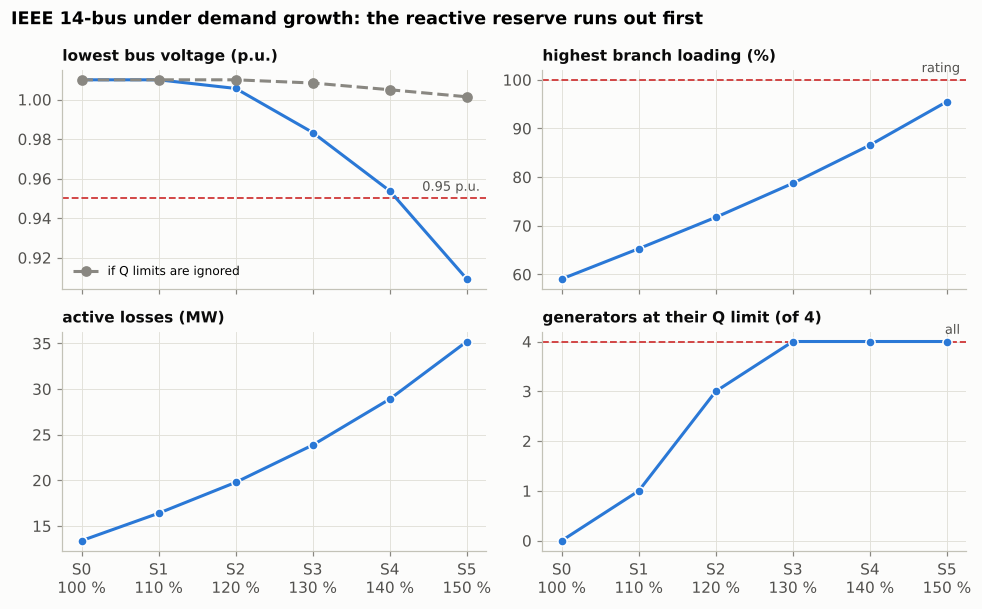

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(9.0, 5.6), sharex=True)
x = np.arange(len(res))
labels = list(scen.keys())
panels = [("min |V| (p.u.)", "lowest bus voltage (p.u.)", 0.95, "0.95 p.u."),
          ("max loading (%)", "highest branch loading (%)", 100, "rating"),
          ("losses (MW)", "active losses (MW)", None, None),
          ("gens at Q limit", "generators at their Q limit (of 4)", 4, "all")]
for ax, (col, title, lim, lab) in zip(axes.ravel(), panels):
    ax.plot(x, res[col].astype(float), "o-", color=SERIES[0], markeredgecolor="white")
    if lim is not None:
        limit_line(ax, lim, lab, color=CRITICAL)
    ax.set_title(title, fontsize=10)
axes[0, 0].plot(x, res_nolim["min |V| (p.u.)"].astype(float), "o--", color=MUTED,
                label="if Q limits are ignored")
axes[0, 0].legend(loc="lower left", fontsize=8)
for ax in axes[1]:
    ax.set_xticks(x); ax.set_xticklabels([f"{s}\n{int(l*100)} %" for s, l in scen.items()])
fig.suptitle("IEEE 14-bus under demand growth: the reactive reserve runs out first",
             x=0.01, ha="left", fontweight="bold", fontsize=11.5)
fig.tight_layout()
save(fig, FIG / "cs05_indicators.png")
fig

## 6. The PV curve: how far can demand grow? (question 7)
We increase $\lambda$ in steps of 0.01 until the load flow no longer has a solution.

In [6]:
def pv_curve(q_limits=True, extra=None, step=0.01):
    out = []
    lam = 1.0
    while lam < 2.5:
        try:
            n, sw = grown(lam, q_limits, extra)
        except Exception:
            break
        v = n.buses_t.v_mag_pu.iloc[0]
        if v.min() < 0.5:                       # low-voltage branch: unrealistic, stop
            break
        out.append({"lambda": lam, "P load (MW)": n.loads.p_set.sum(), "V14": v["14"],
                    "V min": v.min(), "gens at limit": len(sw)})
        lam = round(lam + step, 4)
    return pd.DataFrame(out).set_index("lambda")

pvc = pv_curve()
pvc_nolim = pv_curve(q_limits=False, step=0.05)
cap14 = lambda n: n.add("ShuntImpedance", "cap14", bus="14", b=20 / 132**2)
pvc_cap = pv_curve(extra=cap14)
lam_max = pvc.index.max()
pvc.to_csv(TAB / "cs05_pv_curve.csv")
print(f"Maximum loadability with Q limits: lambda = {lam_max:.2f} "
      f"({pvc['P load (MW)'].max():.0f} MW, margin {100 * (lam_max - 1):.0f} %)")
print(f"With a 20 MVAr capacitor at bus 14: lambda = {pvc_cap.index.max():.2f}")
print(f"Ignoring Q limits: lambda >= {pvc_nolim.index.max():.2f} (optimistic)")

Maximum loadability with Q limits: lambda = 1.77 (458 MW, margin 77 %)
With a 20 MVAr capacitor at bus 14: lambda = 1.81
Ignoring Q limits: lambda >= 2.45 (optimistic)


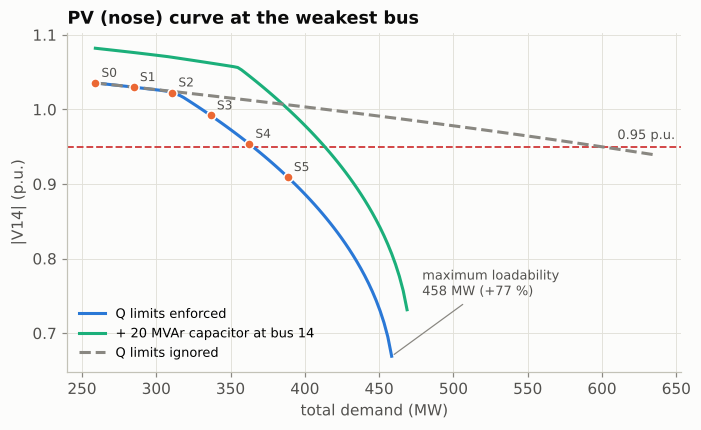

In [7]:
fig, ax = plt.subplots(figsize=(7.2, 4.0))
ax.plot(pvc["P load (MW)"], pvc["V14"], color=SERIES[0], label="Q limits enforced")
ax.plot(pvc_cap["P load (MW)"], pvc_cap["V14"], color=SERIES[2], label="+ 20 MVAr capacitor at bus 14")
ax.plot(pvc_nolim["P load (MW)"], pvc_nolim["V14"], "--", color=MUTED, label="Q limits ignored")
limit_line(ax, 0.95, "0.95 p.u.", color=CRITICAL)
for s, lam in scen.items():
    if lam in pvc.index:
        ax.plot(pvc.loc[lam, "P load (MW)"], pvc.loc[lam, "V14"], "o", color=SERIES[1], ms=6,
                markeredgecolor="white", zorder=3)
        ax.annotate(s, (pvc.loc[lam, "P load (MW)"], pvc.loc[lam, "V14"]), xytext=(4, 4),
                    textcoords="offset points", fontsize=8, color=INK2)
ax.annotate(f"maximum loadability\n{pvc['P load (MW)'].max():.0f} MW (+{100*(lam_max-1):.0f} %)",
            (pvc["P load (MW)"].max(), pvc["V14"].iloc[-1]), xytext=(20, 40),
            textcoords="offset points", fontsize=8.5, color=INK2,
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
ax.set_xlabel("total demand (MW)"); ax.set_ylabel("|V14| (p.u.)")
ax.set_title("PV (nose) curve at the weakest bus")
ax.legend(loc="lower left", fontsize=8.5)
save(fig, FIG / "cs05_pv_curve.png")
fig

## 7. Interpretation
* **S0-S3 (+0 to +30 %):** all voltages stay above 0.95 p.u. and no branch is overloaded.
  Read alone, these indicators say "no problem". But the generators reach their **reactive
  limits** one after another (G2 at +10 %, then the synchronous condensers): at S3 all four
  voltage-controlling units are at their limit. **The voltage-control reserve is gone.**
* **S4-S5 (+40 to +50 %):** voltages drop quickly: bus 14 is just above the limit at S4
  (0.954 p.u.) and **nine buses** are below 0.95 p.u. at S5. Losses rise much faster than
  demand (from 13.4 to 35.2 MW for +50 % demand: they grow with the square of the current),
  and line 1-5 approaches its rating (96 %).
* The **maximum loadability** is about **+77 %** (458 MW) with reactive limits enforced. If
  the limits were ignored the study would wrongly conclude to more than +145 %.
* Beyond the nose point no load-flow solution exists: voltage collapse. A 20 MVAr capacitor
  bank at the weakest bus pushes the limit from +77 % to about +81 %.

**Key message:** a grid can deliver the energy and still violate its operating limits.
Having enough MW of generation does not guarantee that the power can be transported. The
first warning sign is not a low voltage but the **loss of reactive reserve**.

**Recommendations:** reactive compensation at the weak buses (9, 14), voltage-control
capability on new generation, reinforcement of the most loaded corridor (1-5), and
demand-side measures to shave the peak.

In [8]:
pscs.save_summary("cs05", {
    "table": res.drop(columns=["switched"]).to_dict(orient="index"),
    "min_v_nolimits": res_nolim["min |V| (p.u.)"].to_dict(),
    "lambda_max": lam_max, "P_max": pvc["P load (MW)"].max(),
    "lambda_max_cap14": pvc_cap.index.max(), "lambda_nolim": pvc_nolim.index.max(),
})